## Use Bayesian Optimization to further optimize hyperparameters by implementing Gaussian Process Regression for intelligent hyperparameter selection without using existing Bayesian optimization libraries.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('heart.csv')                          
X, y = df.drop(columns='target').values.astype(float), df['target'].values
print(X.shape, '| positive share:', y.mean().round(2))

(303, 13) | positive share: 0.54


In [2]:
def auc(t, s):
    sp, sn = s[t == 1], s[t == 0]
    return (sp[:, None] > sn[None, :]).mean() + 0.5 * (sp[:, None] == sn[None, :]).mean()

def metrics(t, p):
    q = np.clip(p, 1e-6, 1 - 1e-6)
    return dict(acc=np.mean((p > 0.5) == t), auc=auc(t, p), logloss=-np.mean(t * np.log(q) + (1 - t) * np.log(1 - q)))

def make_lr(logC, l1r):                                
    kw = dict(C=10 ** logC, l1_ratio=float(l1r), solver='saga', max_iter=2000)
    if not (sklearn.__version__.startswith('1.') and int(sklearn.__version__.split('.')[1]) >= 8): kw['penalty'] = 'elasticnet'
    return LogisticRegression(**kw)

def make_folds(n, k, seed): return np.array_split(np.random.default_rng(seed).permutation(n), k)

def objective(theta, A, t, fold_seed=0, k=5):
    loss = []
    for f in make_folds(len(t), k, fold_seed):
        tr = np.setdiff1d(np.arange(len(t)), f); mu, sd = A[tr].mean(0), A[tr].std(0)
        p = make_lr(*theta).fit((A[tr] - mu) / sd, t[tr]).predict_proba((A[f] - mu) / sd)[:, 1]
        loss.append(metrics(t[f], p)['logloss'])
    return np.mean(loss)

LO, HI = np.array([-3.0, 0.0]), np.array([2.0, 1.0])   # search space
print('Default LR (C=1, L2) loss:', round(objective((0, 0), X, y), 4), '| Task 20 best (C=0.3, L2):', round(objective((np.log10(0.3), 0), X, y), 4))

Default LR (C=1, L2) loss: 0.3948 | Task 20 best (C=0.3, L2): 0.3899


In [3]:
def rbf(A, B, ls): return np.exp(-0.5 * ((A[:, None, :] - B[None, :, :]) ** 2).sum(2) / ls ** 2)

def gp_fit(Xn, yn, ls, noise):
    L = np.linalg.cholesky(rbf(Xn, Xn, ls) + noise * np.eye(len(Xn)))
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, yn))                        
    lml = -0.5 * yn @ alpha - np.log(np.diag(L)).sum() - 0.5 * len(yn) * np.log(2 * np.pi)   
    return dict(L=L, alpha=alpha, ls=ls, Xn=Xn, lml=lml)

def gp_best(Xn, yn):                                   
    fits = [gp_fit(Xn, yn, ls, nz) for ls in [0.1, 0.2, 0.3, 0.5, 0.8] for nz in [1e-5, 1e-3, 1e-2, 1e-1]]
    return max(fits, key=lambda g: g['lml'])

def gp_predict(g, Q):
    Ks = rbf(Q, g['Xn'], g['ls']); mu = Ks @ g['alpha']
    v = np.linalg.solve(g['L'], Ks.T); var = np.maximum(1 - (v ** 2).sum(0), 1e-12) 
    return mu, np.sqrt(var)

In [4]:
Phi = np.vectorize(lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2))))
phi = lambda z: np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)

def expected_improvement(mu, sd, best, xi=0.01):
    z = (best - mu - xi) / sd
    return (best - mu - xi) * Phi(z) + sd * phi(z)     

In [5]:
def to_unit(T): return (np.atleast_2d(T) - LO) / (HI - LO)
def from_unit(U): return LO + U * (HI - LO)

def bayes_opt(A, t, n_init=5, n_iter=25, seed=0, fold_seed=0):
    rng = np.random.default_rng(seed)
    U = rng.random((n_init, 2)); Y = [objective(from_unit(u), A, t, fold_seed) for u in U]     
    for _ in range(n_iter):
        Y_arr = np.log(np.array(Y)); ym, ys = Y_arr.mean(), Y_arr.std() + 1e-9                  
        g = gp_best(U, (Y_arr - ym) / ys)                                                      
        cand = rng.random((2000, 2)); mu, sd = gp_predict(g, cand)
        ei = expected_improvement(mu, sd, (Y_arr.min() - ym) / ys)
        u_new = cand[np.argmax(ei)]                                                             
        U = np.vstack([U, u_new]); Y.append(objective(from_unit(u_new), A, t, fold_seed))
    return from_unit(U), np.array(Y)

def random_search(A, t, n=30, seed=0, fold_seed=0):
    U = np.random.default_rng(seed).random((n, 2))
    return from_unit(U), np.array([objective(from_unit(u), A, t, fold_seed) for u in U])

In [6]:
runs = {'BO': [], 'Random': []}
for seed in range(5):
    runs['BO'].append(bayes_opt(X, y, seed=seed)); runs['Random'].append(random_search(X, y, seed=seed))
curve = lambda name: np.array([np.minimum.accumulate(Y) for _, Y in runs[name]])      # best-so-far
rows = []
for name in runs:
    c = curve(name); rows.append((name, f'{c[:, 9].mean():.4f}', f'{c[:, 19].mean():.4f}', f'{c[:, -1].mean():.4f} +- {c[:, -1].std():.4f}', f'{c[:, -1].min():.4f}'))
pd.DataFrame(rows, columns=['Method', 'Best loss @10 evals', '@20 evals', '@30 evals (mean +- std)', 'Best of 5 seeds'])

,Method,Best loss @10 evals,@20 evals,@30 evals (mean +- std),Best of 5 seeds
0,BO,0.3931,0.3920,0.3893 +- 0.0003,0.3891
1,Random,0.3933,0.3913,0.3910 +- 0.0009,0.3896


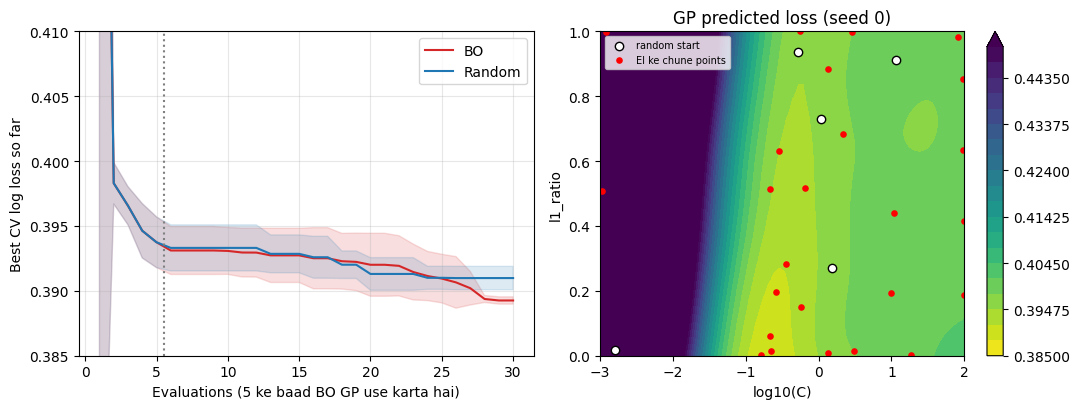

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, c in [('BO', 'tab:red'), ('Random', 'tab:blue')]:
    cv = curve(name); m, s = cv.mean(0), cv.std(0); xs = np.arange(1, 31)
    axes[0].plot(xs, m, color=c, label=name); axes[0].fill_between(xs, m - s, m + s, color=c, alpha=0.15)
axes[0].axvline(5.5, color='gray', ls=':'); axes[0].set_ylim(0.385, 0.41)
axes[0].set_xlabel('Evaluations (5 ke baad BO GP use karta hai)'); axes[0].set_ylabel('Best CV log loss so far'); axes[0].legend(); axes[0].grid(alpha=0.3)
T, Yb = runs['BO'][0]; Yl = np.log(Yb); Ya = (Yl - Yl.mean()) / Yl.std(); g = gp_best(to_unit(T), Ya)
gx, gy = np.meshgrid(np.linspace(0, 1, 60), np.linspace(0, 1, 60)); mu, _ = gp_predict(g, np.c_[gx.ravel(), gy.ravel()])
cs = axes[1].contourf(LO[0] + gx * 5, gy, np.exp(mu * Yl.std() + Yl.mean()).reshape(60, 60), np.linspace(0.385, 0.45, 21), cmap='viridis_r', extend='max')
axes[1].scatter(T[:5, 0], T[:5, 1], c='white', edgecolors='k', label='random start'); axes[1].scatter(T[5:, 0], T[5:, 1], c='red', s=14, label='EI ke chune points')
axes[1].set_xlabel('log10(C)'); axes[1].set_ylabel('l1_ratio'); axes[1].set_title('GP predicted loss (seed 0)'); axes[1].legend(fontsize=7); fig.colorbar(cs, ax=axes[1])
plt.tight_layout(); plt.show()

In [8]:
allT = np.vstack([T for T, _ in runs['BO']]); allY = np.concatenate([Y for _, Y in runs['BO']])
order = np.argsort(allY)[:5]
print('Top 5 BO points (log10 C, l1_ratio, CV log loss):')
for i in order: print(f'  C = {10 ** allT[i, 0]:.3f} (log10 {allT[i, 0]:+.2f}) | l1_ratio = {allT[i, 1]:.2f} | loss = {allY[i]:.4f}')
print('BO evaluations me se l1_ratio < 0.2 wale points:', f'{np.mean(allT[:, 1] < 0.2):.0%}', '| random me:', f"{np.mean(np.vstack([T for T, _ in runs['Random']])[:, 1] < 0.2):.0%}")

Top 5 BO points (log10 C, l1_ratio, CV log loss):
  C = 0.188 (log10 -0.73) | l1_ratio = 0.00 | loss = 0.3891
  C = 0.185 (log10 -0.73) | l1_ratio = 0.00 | loss = 0.3891
  C = 0.197 (log10 -0.71) | l1_ratio = 0.00 | loss = 0.3891
  C = 0.161 (log10 -0.79) | l1_ratio = 0.00 | loss = 0.3892
  C = 0.213 (log10 -0.67) | l1_ratio = 0.01 | loss = 0.3893
BO evaluations me se l1_ratio < 0.2 wale points: 38% | random me: 20%


In [9]:
cand_models = {'Default (C=1, L2)': (0, 0), 'Grid best (C=0.3, L2)': (np.log10(0.3), 0)}
nested = {n: [] for n in list(cand_models) + ['BO tuned']}; picked = []
for rep in range(2):
    folds = make_folds(len(X), 5, 200 + rep)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        T_, Y_ = bayes_opt(X[tr], y[tr], n_init=5, n_iter=15, seed=rep * 5 + k, fold_seed=rep * 5 + k)
        theta = T_[np.argmin(Y_)]; picked.append(theta)
        mu, sd = X[tr].mean(0), X[tr].std(0); A, B = (X[tr] - mu) / sd, (X[te] - mu) / sd
        for name, th in list(cand_models.items()) + [('BO tuned', theta)]:
            nested[name].append(metrics(y[te], make_lr(*th).fit(A, y[tr]).predict_proba(B)[:, 1]))
rows = []; base = np.array([m['logloss'] for m in nested['Default (C=1, L2)']])
for name, ms in nested.items():
    g_ = lambda c: np.array([m[c] for m in ms]); d = g_('logloss') - base
    rows.append((name, f"{g_('acc').mean():.3f} +- {g_('acc').std():.3f}", f"{g_('auc').mean():.3f}", f"{g_('logloss').mean():.4f}", f"{d.mean():+.4f} +- {d.std(ddof=1) / np.sqrt(len(d)):.4f}"))
print(pd.DataFrame(rows, columns=['Model', 'Accuracy', 'AUC', 'Log loss', 'Log loss diff vs Default']).to_string())
P = np.array(picked); print('\nOuter folds me BO ke chune hyperparameters: C median', round(float(10 ** np.median(P[:, 0])), 3), '| l1_ratio median', round(float(np.median(P[:, 1])), 2))

                   Model        Accuracy    AUC Log loss Log loss diff vs Default
0      Default (C=1, L2)  0.817 +- 0.038  0.896   0.4150        +0.0000 +- 0.0000
1  Grid best (C=0.3, L2)  0.818 +- 0.037  0.898   0.4061        -0.0089 +- 0.0026
2               BO tuned  0.817 +- 0.031  0.898   0.4043        -0.0107 +- 0.0047

Outer folds me BO ke chune hyperparameters: C median 0.19 | l1_ratio median 0.01
